# Per-edge independent basis selection

This notebook gives every edge the full 34-curve library and an L1 ("LASSO") penalty on the edge coefficients, and lets training decide which basis curves each edge uses, independently per edge.

**Setup**: identical to the existing `[2,2,1]` experiment in
`affine_kan_2-2-1_consistent.ipynb`. Same target function
`y = 0.3*x1^2 + cos(3*x2)`, same `torch.manual_seed(42)`, same
train/test sizes (1000/300), same affine-mapping ranges
(`input_neg_max=[0.2, 3.0]`, `input_pos_max=[1.0, 3.0]`,
`basis_min=0.05`, `basis_max=2.0`), same hidden size `[2]`, same
optimizer/epochs (Adam, lr=1e-3, 5000 epochs), same float64 precision.

In [51]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import os

from importlib import reload
import kan
reload(kan)

import kan_sparse_basis
reload(kan_sparse_basis)
from kan_sparse_basis import SparseKAN, load_full_basis_library, estimate_hidden_ranges

## 1. Load the full basis library

In [ ]:
mat_path = "activation_KAN_fit_B_Sofija_extend_positive_basisKAN.mat"

b_coef, input_power, peakout_data, set_detuning = load_full_basis_library(mat_path)

print("Full library shape:", b_coef.shape)        # every candidate curve
print("Detuning range (GHz):", float(set_detuning.min()), "to", float(set_detuning.max()))

mat_folder = "sparse_221_exports"
os.makedirs(mat_folder, exist_ok=True)

Full library shape: torch.Size([34, 8])
Detuning range (GHz): -380000010240.0 to -49999998976.0


## 2. Data loading

In [53]:
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

n_train = 1000
n_test = 300

x_min_test = 0
x_max_test = 1

x_train = x_min_test + (x_max_test - x_min_test) * torch.rand(n_train, 2)
x_test = x_min_test + (x_max_test - x_min_test) * torch.rand(n_test, 2)

def target_fn(x):
    x1 = x[:, 0:1]
    x2 = x[:, 1:2]
    y = 0.3 * x1**2 + torch.cos(3.0 * x2)
    return y

y_train = target_fn(x_train)
y_test = target_fn(x_test)

# float64 throughout
x_train = x_train.double()
y_train = y_train.double()
x_test = x_test.double()
y_test = y_test.double()

## 3. Calibrate the hidden layer's range

`input_neg_max=[0.2, 3.0], input_pos_max=[1.0, 3.0]` is what the `affine_kan_2-2-1` notebook uses for layer 1. The value `3.0` was calibrated for an edge with only 8 free coefficients. With up to 34 free coefficients per edge, the same layer's raw output can range much
wider, and it can drift past what the next layer's affine map assumes. Therefore, `layer 1`'s
range is calibrated properly first: train a disposable probe model briefly with a generous placeholder range; read off the largest value it actually produced; use it with a safety
margin for the real run. `estimate_hidden_ranges` automates the previously manual loop.

In [54]:
build_kwargs = dict(
    in_count=2,
    out_count=1,
    hidden_layer_sizes=[2],
    x_min=float(input_power.min()),
    x_max=float(input_power.max()),
    layer_type="photonic_interval_affine_clean",
    b_coef_selected=b_coef,          # full library, not a picked subset
    input_neg_max=[0.2, 3.0],        # layer 0 entry (0.2) is real and kept as is;
    input_pos_max=[1.0, 3.0],        # the 3.0 is just a placeholder estimate_hidden_ranges replaces
    basis_min=0.05,
    basis_max=2.0,
    dropout_prob=0.0,
    debug=False,
)

lam = 8e-5   # sparsity penalty weight --> calibrate with the same lam you will train with

calibrated_neg_max, calibrated_pos_max = estimate_hidden_ranges(
    build_kwargs, x_train, y_train, nn.MSELoss(),
    lam=lam, probe_epochs=200, probe_range=10.0, margin=1.5, seed=42,
)
print("Calibrated input_neg_max:", calibrated_neg_max)
print("Calibrated input_pos_max:", calibrated_pos_max)

Calibrated input_neg_max: [0.2, 11.979667240722307]
Calibrated input_pos_max: [1.0, 11.979667240722307]


In [55]:
model = SparseKAN(
    **{**build_kwargs, "input_neg_max": calibrated_neg_max, "input_pos_max": calibrated_pos_max}
)

model = model.to(device=device, dtype=torch.float64)

print("num_basis per layer:", [layer.num_basis for layer in model.layers])
print("Total trainable edge coefficients:",
      sum(layer.coeffs.numel() for layer in model.layers))

num_basis per layer: [34, 34]
Total trainable edge coefficients: 204


## 4. Train with an L1 sparsity penalty on the edge coefficients

`loss = MSE(pred, target) + lam * model.l1_penalty()`. Everything else
(optimizer, learning rate, epoch count, float64 precision) matches the
baseline `[2,2,1]` run.

`lam=8e-5`

In [56]:
x_train = x_train.to(device=device, dtype=torch.float64)
y_train = y_train.to(device=device, dtype=torch.float64)
x_test = x_test.to(device=device, dtype=torch.float64)
y_test = y_test.to(device=device, dtype=torch.float64)

optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

num_epochs = 5000
# lam is set above (used for the calibration probe too)

train_losses = []     # MSE only
test_losses = []      # MSE only
l1_values = []        # sum(|coeffs|)

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()

    y_pred = model(x_train)
    mse = loss_fn(y_pred, y_train)
    l1 = model.l1_penalty()
    loss = mse + lam * l1

    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        y_test_pred = model(x_test)
        test_mse = loss_fn(y_test_pred, y_test)

    train_losses.append(mse.item())
    test_losses.append(test_mse.item())
    l1_values.append(l1.item())

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch:5d} | "
            f"train MSE = {mse.item():.8f} | "
            f"test MSE = {test_mse.item():.8f} | "
            f"sum|coeffs| = {l1.item():.4f}"
        )

Epoch     0 | train MSE = 0.56180422 | test MSE = 0.52169205 | sum|coeffs| = 1.4719
Epoch   500 | train MSE = 0.00084480 | test MSE = 0.00067186 | sum|coeffs| = 10.1254
Epoch  1000 | train MSE = 0.00012473 | test MSE = 0.00010008 | sum|coeffs| = 7.5270
Epoch  1500 | train MSE = 0.00005802 | test MSE = 0.00004606 | sum|coeffs| = 5.8582
Epoch  2000 | train MSE = 0.00003254 | test MSE = 0.00002595 | sum|coeffs| = 4.8070
Epoch  2500 | train MSE = 0.00002146 | test MSE = 0.00001695 | sum|coeffs| = 4.5257
Epoch  3000 | train MSE = 0.00002298 | test MSE = 0.00002004 | sum|coeffs| = 4.3219
Epoch  3500 | train MSE = 0.00001808 | test MSE = 0.00001576 | sum|coeffs| = 4.1435
Epoch  4000 | train MSE = 0.00001176 | test MSE = 0.00000963 | sum|coeffs| = 3.9904
Epoch  4500 | train MSE = 0.00001002 | test MSE = 0.00000904 | sum|coeffs| = 3.8704


In [57]:
model.eval()

with torch.no_grad():
    y_pred_train = model(x_train)
    y_pred_test = model(x_test)

    train_mse = nn.functional.mse_loss(y_pred_train, y_train)
    test_mse = nn.functional.mse_loss(y_pred_test, y_test)

print(f"Final train MSE: {train_mse.item():.10f}")
print(f"Final test MSE:  {test_mse.item():.10f}")


Final train MSE: 0.0000117136
Final test MSE:  0.0000110756


## 5. Training curves

Saved MATLAB plot data to: sparse_221_exports/loss_curves.mat


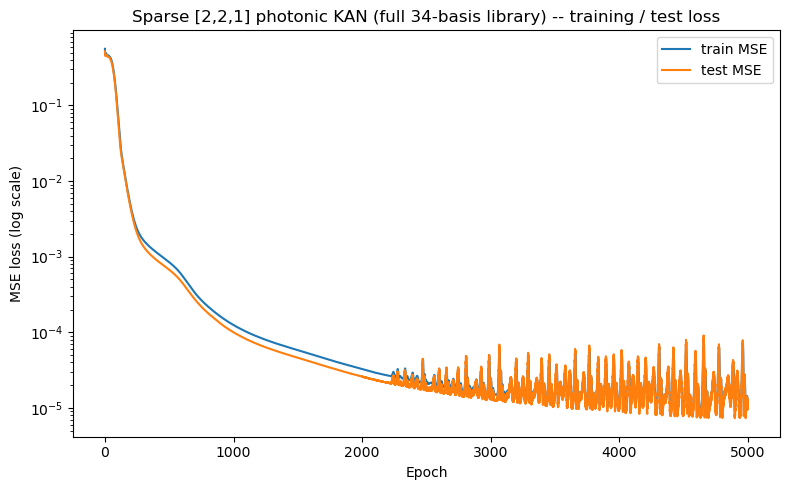

In [58]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_losses, label="train MSE")
ax.plot(test_losses, label="test MSE")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (log scale)")
ax.set_title("Sparse [2,2,1] photonic KAN (full 34-basis library) -- training / test loss")
ax.legend()
plt.tight_layout()
kan.export_plot_data_to_mat(
    "loss_curves.mat",
    {"epoch": np.arange(num_epochs), "train_mse": np.array(train_losses),
     "test_mse": np.array(test_losses), "l1_values": np.array(l1_values)},
    export_dir=mat_folder,
)
plt.savefig(os.path.join(mat_folder, "sparse_221_loss_curve.png"))
plt.show()

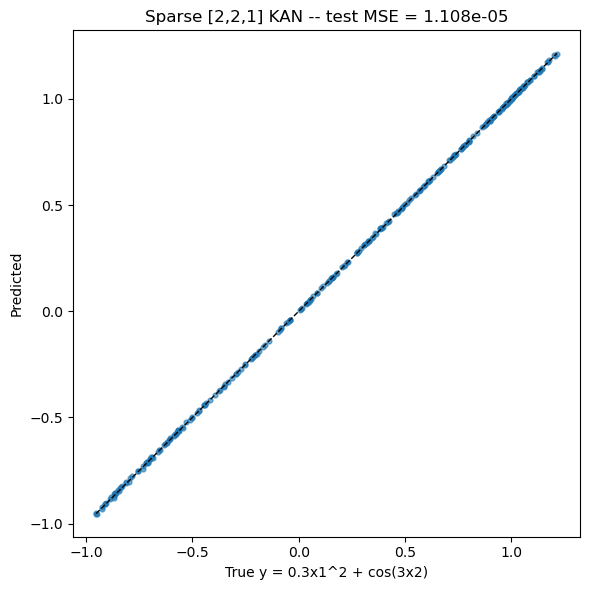

In [59]:
fig, ax = plt.subplots(figsize=(6, 6))
y_pred_test_np = y_pred_test.detach().cpu().numpy().ravel()
y_test_np = y_test.detach().cpu().numpy().ravel()
ax.scatter(y_test_np, y_pred_test_np, s=12, alpha=0.6)
lims = [min(y_test_np.min(), y_pred_test_np.min()), max(y_test_np.max(), y_pred_test_np.max())]
ax.plot(lims, lims, "k--", linewidth=1)
ax.set_xlabel("True y = 0.3x1^2 + cos(3x2)")
ax.set_ylabel("Predicted")
ax.set_title(f"Sparse [2,2,1] KAN -- test MSE = {test_mse.item():.3e}")
plt.tight_layout()
plt.savefig(os.path.join(mat_folder, "sparse_221_true_vs_pred.png"))
plt.show()

## 6. Basis functions per edge

In [60]:
report = model.summarize_active_basis(threshold=1e-3)

layer  out   in  active/total  active basis indices
    0    0    0      9/34    [0,1,2,7,8,9,10,11,12]
    0    0    1      9/34    [0,1,2,6,7,8,9,10,11]
    0    1    0      4/34    [5,6,9,10]
    0    1    1      6/34    [6,7,8,9,10,11]
    1    0    0     11/34    [0,1,2,3,4,5,6,7,8,9,10]
    1    0    1     10/34    [0,1,2,3,4,6,7,8,9,10]

Active basis count per edge (threshold=0.001): min=4, mean=8.17, max=11


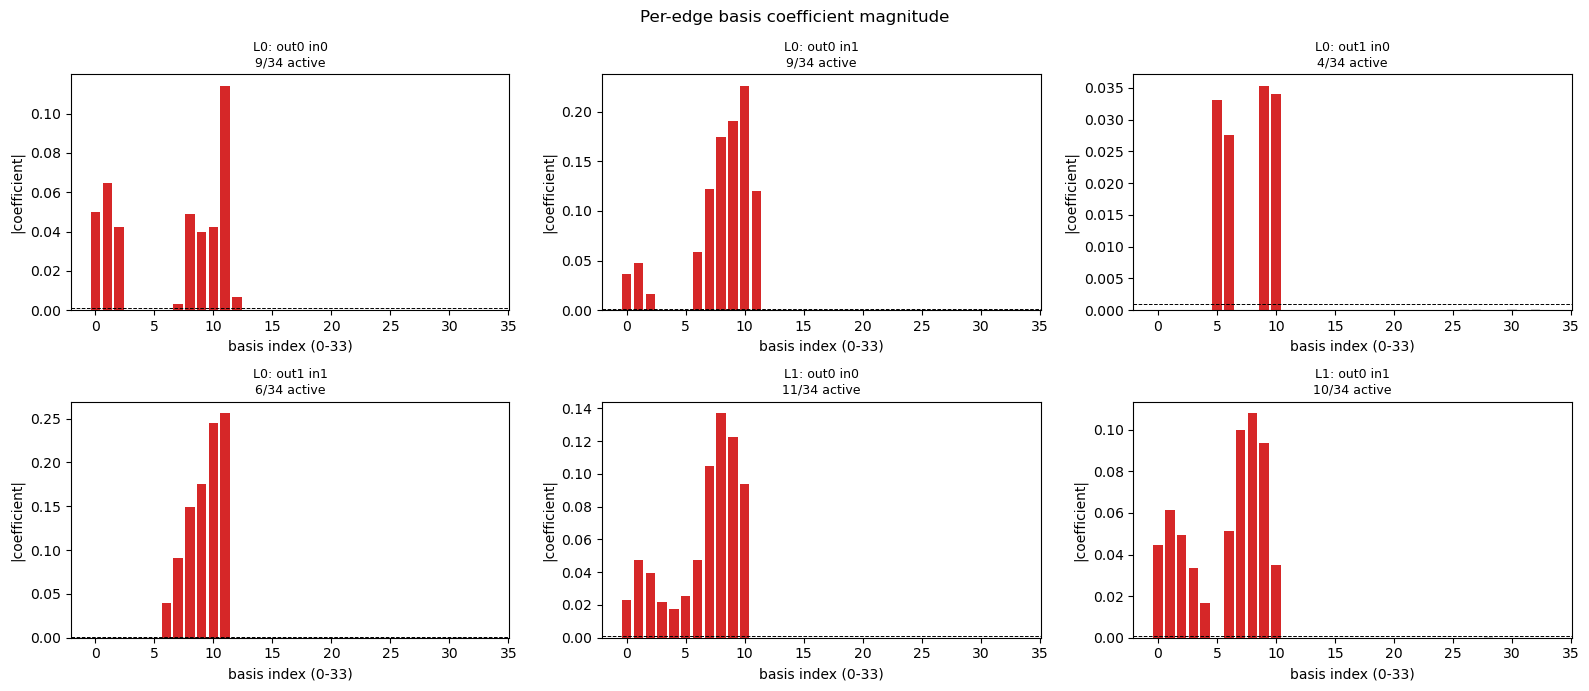

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
edge_labels = [
    "L0: out0 in0", "L0: out0 in1",
    "L0: out1 in0", "L0: out1 in1",
    "L1: out0 in0", "L1: out0 in1",
]
for ax, r, label in zip(axes.ravel(), report, edge_labels):
    layer = model.layers[r["layer"]]
    coeffs = model._get_layer_coeffs(layer).detach()[r["out_idx"], r["in_idx"]].cpu().numpy()
    colors = ["tab:red" if abs(c) > 1e-3 else "lightgray" for c in coeffs]
    ax.bar(np.arange(len(coeffs)), np.abs(coeffs), color=colors)
    ax.axhline(1e-3, color="black", linestyle="--", linewidth=0.7)
    ax.set_title(f"{label}\n{r['num_active']}/{r['num_total']} active", fontsize=9)
    ax.set_xlabel("basis index (0-33)")
    ax.set_ylabel("|coefficient|")
fig.suptitle("Per-edge basis coefficient magnitude")
plt.tight_layout()
plt.savefig(os.path.join(mat_folder, "sparse_221_active_basis_bars.png"))
plt.show()

## `threshold=1e-3` instead of `lam`

`summarize_active_basis`/`active_basis_report` take their own `threshold`
(default `1e-3`), separate from the `lam` during training time above.
They are not interchangeable because of how this model is actually trained:
`l1_penalty()` is added to the loss and backpropagated through with Adam
(which is a *subgradient* method), not applied as the exact ISTA proximal operator
($a \leftarrow sign(a)*max(|a|-lam, 0)$) that would make `lam` a literal
per-coefficient cutoff. Under plain subgradient descent, coefficients decay
toward small values but never hit exactly 0. The plot below shows this - each of 204
trained coefficient's magnitude is sorted on a log scale, and `lam` and
`threshold` are marked. If `lam` were the natural cutoff, it would line up with
whatever gap separates small from large coefficients, which it does not here.

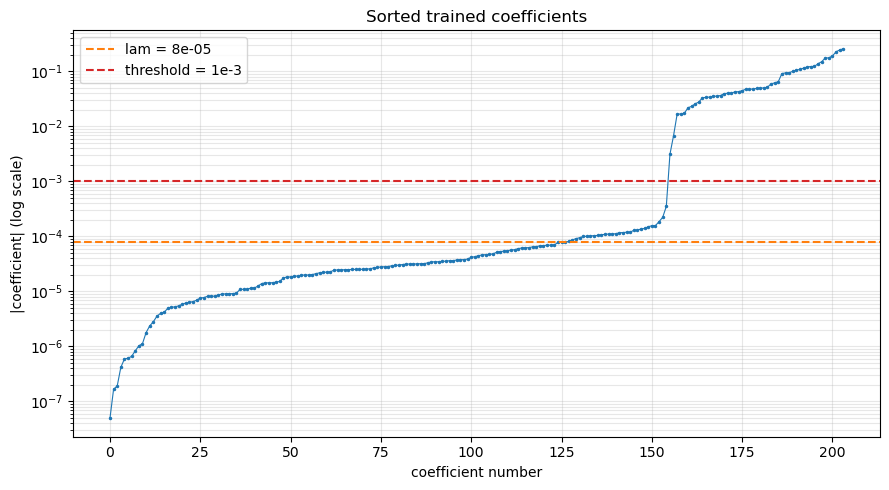

coefficients below threshold=1e-3: 155 / 204
coefficients below lam=8e-05:      127 / 204
smallest coefficient magnitude: 4.928e-08
largest coefficient below threshold:  3.499e-04
smallest coefficient above threshold: 3.088e-03  (8.8x jump)


In [62]:
all_coeffs = torch.cat([l.coeffs.detach().abs().flatten() for l in model.layers]).cpu().numpy()
sorted_coeffs = np.sort(all_coeffs)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sorted_coeffs, marker=".", markersize=3, linestyle="-", linewidth=0.8)
ax.set_yscale("log")
ax.axhline(lam, color="tab:orange", linestyle="--", label=f"lam = {lam:.0e}")
ax.axhline(1e-3, color="tab:red", linestyle="--", label="threshold = 1e-3")
ax.set_xlabel("coefficient number")
ax.set_ylabel("|coefficient| (log scale)")
ax.set_title("Sorted trained coefficients")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(mat_folder, "sparse_221_coeff_magnitude_gap.png"))
plt.show()

num_below_thresh = int((sorted_coeffs < 1e-3).sum())
num_below_lam = int((sorted_coeffs < lam).sum())
print(f"coefficients below threshold=1e-3: {num_below_thresh} / {len(sorted_coeffs)}")
print(f"coefficients below lam={lam:.0e}:      {num_below_lam} / {len(sorted_coeffs)}")
print(f"smallest coefficient magnitude: {sorted_coeffs[0]:.3e}")
if num_below_thresh < len(sorted_coeffs):
    print(f"largest coefficient below threshold:  {sorted_coeffs[num_below_thresh - 1]:.3e}")
    print(f"smallest coefficient above threshold: {sorted_coeffs[num_below_thresh]:.3e}  "
          f"({sorted_coeffs[num_below_thresh] / max(sorted_coeffs[num_below_thresh - 1], 1e-300):.1f}x jump)")

## 7. Accuracy / sparsity trade-off across a `lam` sweep

This comparison sweep is run for 2000 epochs at a few different penalty strengths. Each `lam` gets its own calibration call first, since the realized hidden-layer range depends on how strongly the coefficients are being pulled toward zero.

In [63]:
def run_sparse_221(lam, epochs=2000, seed=42):
    torch.manual_seed(seed)
    xt = torch.rand(n_train, 2, dtype=torch.float64)
    xv = torch.rand(n_test, 2, dtype=torch.float64)
    yt = target_fn(xt)
    yv = target_fn(xv)

    sweep_build_kwargs = dict(
        in_count=2, out_count=1, hidden_layer_sizes=[2],
        x_min=float(input_power.min()), x_max=float(input_power.max()),
        layer_type="photonic_interval_affine_clean",
        b_coef_selected=b_coef,
        input_neg_max=[0.2, 3.0], input_pos_max=[1.0, 3.0],
        basis_min=0.05, basis_max=2.0,
    )
    neg, pos = estimate_hidden_ranges(
        sweep_build_kwargs, xt, yt, nn.MSELoss(),
        lam=lam, probe_epochs=200, probe_range=10.0, margin=1.5, seed=seed,
    )

    m = SparseKAN(
        **{**sweep_build_kwargs, "input_neg_max": neg, "input_pos_max": pos}
    ).to(dtype=torch.float64)

    opt = optim.Adam(m.parameters(), lr=1e-3)
    lf = nn.MSELoss()
    for _ in range(epochs):
        m.train(); opt.zero_grad()
        pred = m(xt)
        mse = lf(pred, yt)
        loss = mse + lam * m.l1_penalty()
        loss.backward(); opt.step()

    m.eval()
    with torch.no_grad():
        test_mse = lf(m(xv), yv).item()
    rep = m.active_basis_report(threshold=1e-3)
    counts = [r["num_active"] for r in rep]
    return test_mse, counts

print(f"{'lam':>10} {'test MSE':>12} {'active basis count per edge (6 edges)':>45} {'mean active':>12}")
for lam_try in [0.0, 1e-5, 3e-5, 8e-5, 1.5e-4, 2e-4, 5e-4, 1e-3, 1e-2]:
    test_mse_try, counts_try = run_sparse_221(lam_try)
    print(f"{lam_try:>10} {test_mse_try:>12.3e} {str(counts_try):>45} {np.mean(counts_try):>12.2f}")

       lam     test MSE         active basis count per edge (6 edges)  mean active
       0.0    6.286e-05                      [34, 34, 32, 34, 34, 34]        33.67
     1e-05    5.302e-05                      [15, 33, 13, 34, 34, 27]        26.00
     3e-05    5.235e-05                      [13, 25, 11, 26, 28, 20]        20.50
     8e-05    5.655e-05                       [12, 14, 8, 13, 19, 11]        12.83
   0.00015    6.262e-05                       [11, 11, 8, 11, 13, 10]        10.67
    0.0002    6.349e-05                        [9, 11, 8, 11, 11, 10]        10.00
    0.0005    7.385e-05                          [8, 7, 5, 6, 11, 10]         7.83
     0.001    1.309e-04                          [7, 6, 0, 6, 10, 10]         6.50
      0.01    4.965e-04                            [4, 4, 0, 2, 7, 8]         4.17


## 8. Shared-subset variant: group lasso comparison

`group_penalty()` groups coefficients by basis index across every edge in a layer instead of
penalizing each (edge, basis-curve) pair independently. The idea is to drive a whole basis curve to zero simultaneously for every edge in the layer, recovering the same kind of shared basis library the original `affine_kan` uses, except now chosen by training. Same architecture, data, seed, and training budget as section 4; only the penalty term changes
(`model.group_penalty()` in place of `model.l1_penalty()`).

In [64]:
lam_group = 8e-4   # group-lasso penalty weight

calibrated_neg_max_group, calibrated_pos_max_group = estimate_hidden_ranges(
    build_kwargs, x_train, y_train, nn.MSELoss(),
    lam=lam_group, probe_epochs=200, probe_range=10.0, margin=1.5, seed=42,
)

model_group = SparseKAN(
    **{**build_kwargs, "input_neg_max": calibrated_neg_max_group, "input_pos_max": calibrated_pos_max_group}
).to(device=device, dtype=torch.float64)

optimizer_group = optim.Adam(model_group.parameters(), lr=1e-3)

train_losses_group = []
test_losses_group = []

for epoch in range(num_epochs):
    model_group.train()
    optimizer_group.zero_grad()

    y_pred = model_group(x_train)
    mse = loss_fn(y_pred, y_train)
    loss = mse + lam_group * model_group.group_penalty()

    loss.backward()
    optimizer_group.step()

    model_group.eval()
    with torch.no_grad():
        test_mse_g = loss_fn(model_group(x_test), y_test)

    train_losses_group.append(mse.item())
    test_losses_group.append(test_mse_g.item())

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:5d} | train MSE = {mse.item():.8f} | test MSE = {test_mse_g.item():.8f}")

print(f"\nFinal train MSE (group lasso): {train_losses_group[-1]:.10f}")
print(f"Final test MSE  (group lasso): {test_losses_group[-1]:.10f}")

Epoch     0 | train MSE = 0.56180176 | test MSE = 0.52169097
Epoch  1000 | train MSE = 0.00013882 | test MSE = 0.00011312
Epoch  2000 | train MSE = 0.00006219 | test MSE = 0.00005242
Epoch  3000 | train MSE = 0.00005960 | test MSE = 0.00004873
Epoch  4000 | train MSE = 0.00005631 | test MSE = 0.00004638

Final train MSE (group lasso): 0.0000733206
Final test MSE  (group lasso): 0.0000632327


In [65]:
report_group = model_group.summarize_active_basis(threshold=1e-3)

layer  out   in  active/total  active basis indices
    0    0    0      6/34    [6,7,8,9,10,11]
    0    0    1      6/34    [6,7,8,9,10,11]
    0    1    0      6/34    [6,7,8,9,10,11]
    0    1    1      6/34    [6,7,8,9,10,11]
    1    0    0      9/34    [0,1,2,3,4,6,7,8,9]
    1    0    1      9/34    [0,1,2,3,4,6,7,8,9]

Active basis count per edge (threshold=0.001): min=6, mean=7.00, max=9


In [66]:
def active_summary(rep):
    counts = [r["num_active"] for r in rep]
    return f"min={min(counts)}, mean={np.mean(counts):.2f}, max={max(counts)}"

print(f"{'Configuration':38} {'Test MSE':>12}   {'Active basis per edge':>28}")
print(f"{'Baseline (hand-picked, 8 curves)':38} {2.722e-05:>12.3e}   {'8 (fixed, every edge)':>28}")
print(f"{'Sparse, per-edge independent (l1)':38} {test_losses[-1]:>12.3e}   {active_summary(report):>28}")
print(f"{'Sparse, shared subset (group lasso)':38} {test_losses_group[-1]:>12.3e}   {active_summary(report_group):>28}")

Configuration                              Test MSE          Active basis per edge
Baseline (hand-picked, 8 curves)          2.722e-05          8 (fixed, every edge)
Sparse, per-edge independent (l1)         1.108e-05       min=4, mean=8.17, max=11
Sparse, shared subset (group lasso)       6.323e-05        min=6, mean=7.00, max=9


## 9. Train without an L1 penalty on a pre-determined basis subset

Both sparse models above were trained with the sparsity penalty. That is standard Lasso/group-lasso behavior, but it comes with a known side effect: the penalty doesn't just zero out the *irrelevant* coefficients, it also shrinks the *surviving* ones.

Another experiment is carried out: taking the architecture decision the penalized run made (which (edge, basis-curve) pairs are allowed to be nonzero), and training a new, freshly initialized model on `loss = MSE` alone, for the same number of epochs as the original run
(`kan_sparse_basis.py`'s `freeze_mask_`).

In [67]:
keep_masks_l1 = [(l.coeffs.detach().abs() > 1e-3).float() for l in model.layers]
keep_masks_group = [(l.coeffs.detach().abs() > 1e-3).float() for l in model_group.layers]

### 9a. Per-edge independent (l1) model

In [68]:
model_refit = SparseKAN(
    **{**build_kwargs, "input_neg_max": calibrated_neg_max, "input_pos_max": calibrated_pos_max}
).to(device=device, dtype=torch.float64)
model_refit.freeze_mask_(keep_masks_l1)   # same architecture

optimizer_refit = optim.Adam(model_refit.parameters(), lr=1e-3)
for epoch in range(num_epochs):   # same epoch number
    model_refit.train()
    optimizer_refit.zero_grad()
    loss = loss_fn(model_refit(x_train), y_train)   # MSE only
    loss.backward()
    optimizer_refit.step()

model_refit.eval()
with torch.no_grad():
    train_mse_refit = loss_fn(model_refit(x_train), y_train).item()
    test_mse_refit = loss_fn(model_refit(x_test), y_test).item()
report_refit = model_refit.active_basis_report(threshold=1e-3)
active_refit = [r["num_active"] for r in report_refit]

print("Per-edge independent (l1) model:")
print(f"  before refitting (original run): test={test_losses[-1]:.4e}")
print(f"  after refitting: train={train_mse_refit:.4e}  test={test_mse_refit:.4e}")
print(f"  active basis counts match the discovered mask: {active_refit == [r['num_active'] for r in report]} ({active_refit})")

Per-edge independent (l1) model:
  before refitting (original run): test=1.1076e-05
  after refitting: train=8.0646e-06  test=7.1200e-06
  active basis counts match the discovered mask: True ([9, 9, 4, 6, 11, 10])


### 9b. Shared-subset (group lasso) model

In [76]:
model_group_refit = SparseKAN(
    **{**build_kwargs, "input_neg_max": calibrated_neg_max_group, "input_pos_max": calibrated_pos_max_group}
).to(device=device, dtype=torch.float64)
model_group_refit.freeze_mask_(keep_masks_group)

optimizer_refit_g = optim.Adam(model_group_refit.parameters(), lr=1e-3)
for epoch in range(num_epochs):   # same number of epochs
    model_group_refit.train()
    optimizer_refit_g.zero_grad()
    loss = loss_fn(model_group_refit(x_train), y_train)
    loss.backward()
    optimizer_refit_g.step()

model_group_refit.eval()
with torch.no_grad():
    train_mse_g_refit = loss_fn(model_group_refit(x_train), y_train).item()
    test_mse_g_refit = loss_fn(model_group_refit(x_test), y_test).item()
report_group_refit = model_group_refit.active_basis_report(threshold=1e-3)
active_g_refit = [r["num_active"] for r in report_group_refit]

print("Shared-subset (group lasso) model:")
print(f"  before refitting (original run): test={test_losses_group[-1]:.4e}")
print(f"  after refitting: train={train_mse_g_refit:.4e}  test={test_mse_g_refit:.4e}")
print(f"  active basis counts match the discovered mask: {active_g_refit == [r['num_active'] for r in report_group]} ({active_g_refit})")

Shared-subset (group lasso) model:
  before refitting (original run): test=6.3233e-05
  after refitting: train=6.9169e-06  test=6.1479e-06
  active basis counts match the discovered mask: False ([6, 6, 5, 6, 9, 9])


In [77]:
print(f"{'Configuration':38} {'Test MSE':>12}   {'Active basis per edge':>28}")
print(f"{'Baseline (hand-picked, 8 curves)':38} {2.722e-05:>12.3e}   {'8 (fixed, every edge)':>28}")
print(f"{'Sparse, per-edge (l1)':38} {test_losses[-1]:>12.3e}   {active_summary(report):>28}")
print(f"{'  + refit':38} {test_mse_refit:>12.3e}   {active_summary(report_refit):>28}")
print(f"{'Sparse, group lasso':38} {test_losses_group[-1]:>12.3e}   {active_summary(report_group):>28}")
print(f"{'  + refit':38} {test_mse_g_refit:>12.3e}   {active_summary(report_group_refit):>28}")

Configuration                              Test MSE          Active basis per edge
Baseline (hand-picked, 8 curves)          2.722e-05          8 (fixed, every edge)
Sparse, per-edge (l1)                     1.108e-05       min=4, mean=8.17, max=11
  + refit                                 7.120e-06       min=4, mean=8.17, max=11
Sparse, group lasso                       6.323e-05        min=6, mean=7.00, max=9
  + refit                                 6.148e-06        min=5, mean=6.83, max=9


For both penalty types, refitting from scratch beats the originally penalized run.

## 10. Basis functions and target approximation

### 10a. Per-edge independent (l1) model

hidden min: -7.0636314094521575
hidden max: 2.730718615711605
Saved MATLAB plot data to: sparse_221_exports/sparse_l1_basis_functions_L0_in0.mat


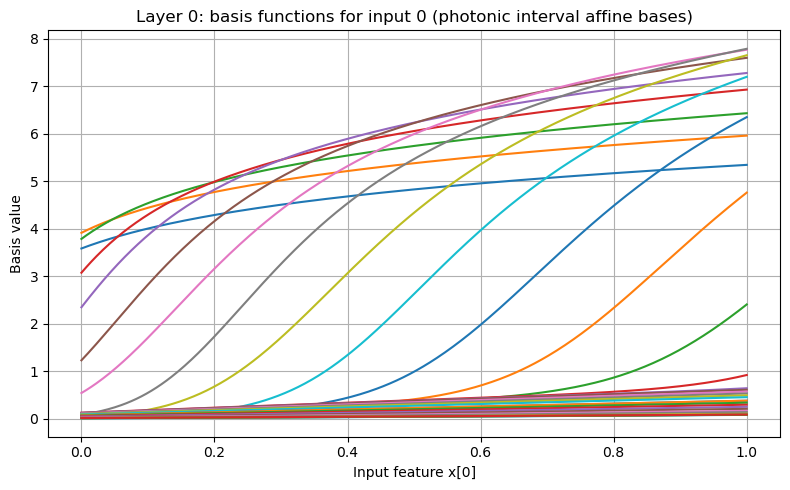

Saved MATLAB plot data to: sparse_221_exports/sparse_l1_basis_functions_L0_in1.mat


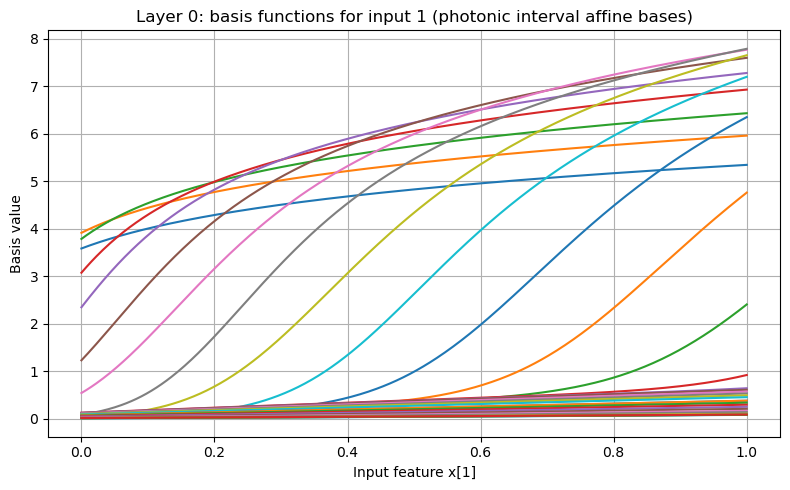

Saved MATLAB plot data to: sparse_221_exports/sparse_l1_basis_functions_L1_in0.mat


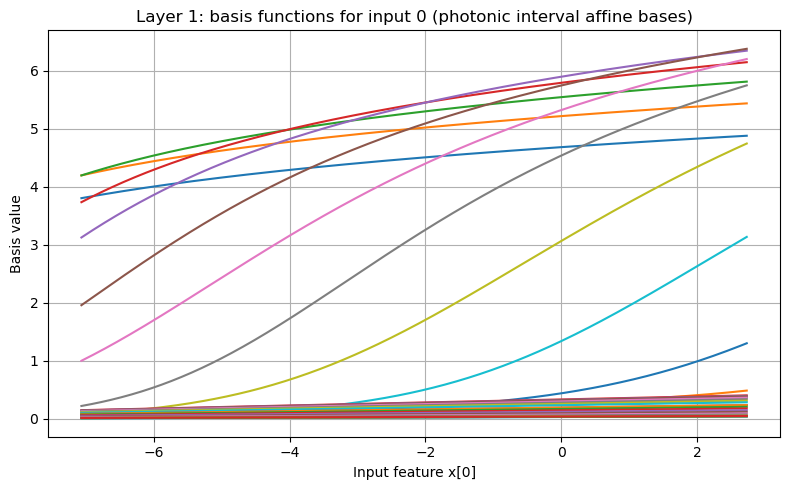

Saved MATLAB plot data to: sparse_221_exports/sparse_l1_basis_functions_L1_in1.mat


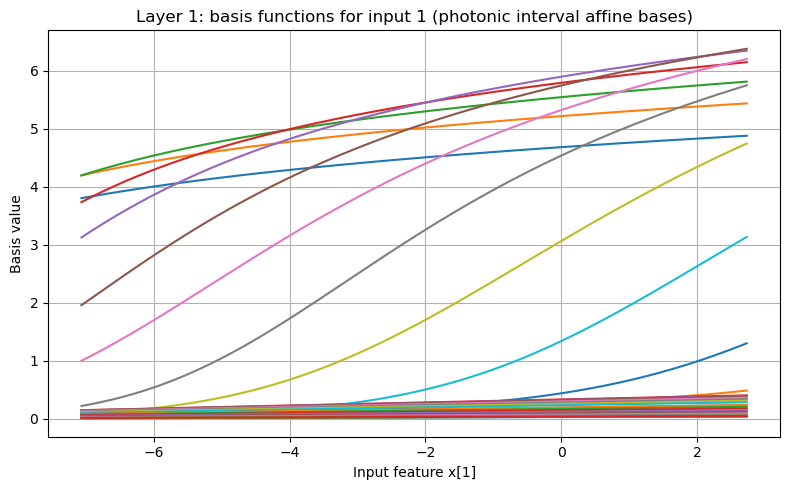

In [78]:
model.eval()
with torch.no_grad():
    _, activations = model(x_train, return_all=True)
z = activations[1]
z_min, z_max = z.min().item(), z.max().item()
print("hidden min:", z_min)
print("hidden max:", z_max)

model.plot_basis_functions(layer_idx=0, in_idx=0, x_range=(x_min_test, x_max_test),
                                  mat_export_path="sparse_l1_basis_functions_L0_in0.mat", mat_export_dir=mat_folder)
model.plot_basis_functions(layer_idx=0, in_idx=1, x_range=(x_min_test, x_max_test),
                                  mat_export_path="sparse_l1_basis_functions_L0_in1.mat", mat_export_dir=mat_folder)
model.plot_basis_functions(layer_idx=1, in_idx=0, x_range=(z_min, z_max),
                                  mat_export_path="sparse_l1_basis_functions_L1_in0.mat", mat_export_dir=mat_folder)
model.plot_basis_functions(layer_idx=1, in_idx=1, x_range=(z_min, z_max),
                                  mat_export_path="sparse_l1_basis_functions_L1_in1.mat", mat_export_dir=mat_folder)

Saved MATLAB plot data to: sparse_221_exports/sparse_l1_target_approximation_0.5_varied_x0.mat


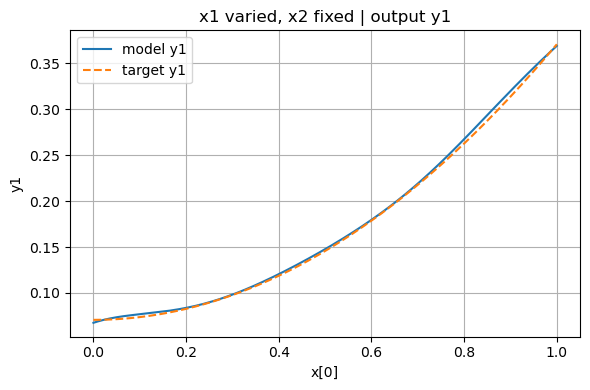

Saved MATLAB plot data to: sparse_221_exports/sparse_l1_target_approximation_0.5_varied_x1.mat


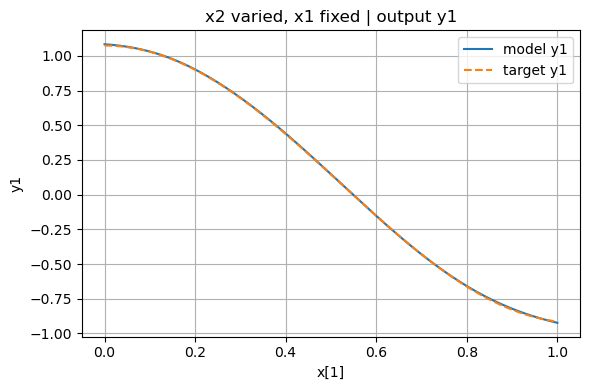

In [79]:
model.plot_target_approximation(
    target_fn=target_fn,
    x_range=(x_min_test, x_max_test),
    fixed_values=[0.5, 0.5],
    resolution=400,
    mat_export_prefix="sparse_l1_target_approximation_0.5",
    mat_export_dir=mat_folder,
)

### 10b. Shared-subset (group lasso) model

hidden min: -5.436660956242468
hidden max: 1.5129822596018958
Saved MATLAB plot data to: sparse_221_exports/sparse_group_basis_functions_L0_in0.mat


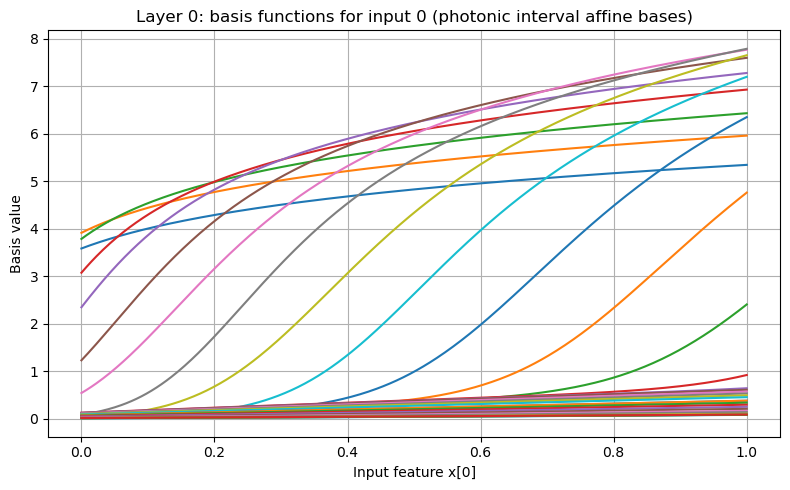

Saved MATLAB plot data to: sparse_221_exports/sparse_group_basis_functions_L0_in1.mat


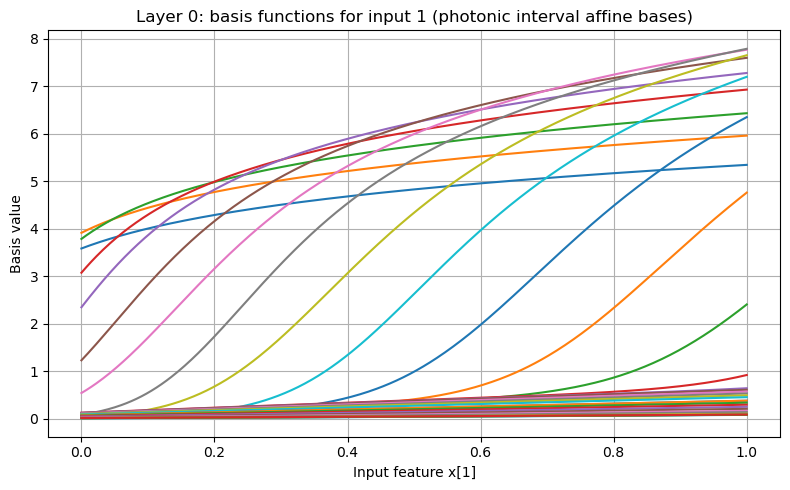

Saved MATLAB plot data to: sparse_221_exports/sparse_group_basis_functions_L1_in0.mat


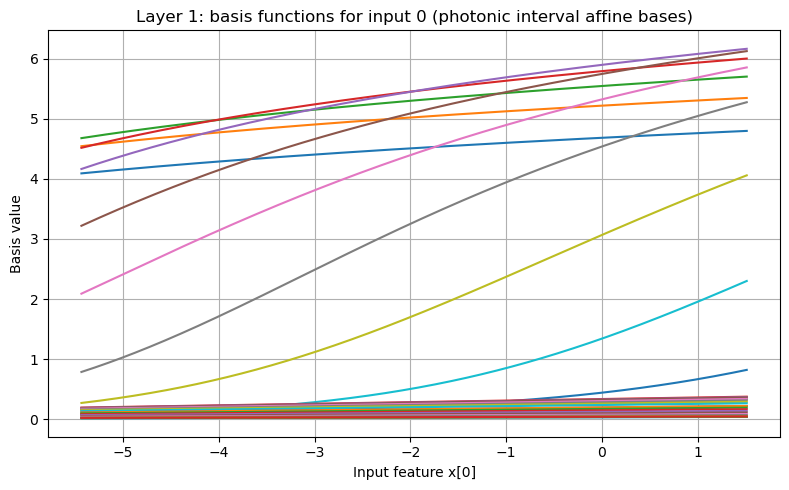

Saved MATLAB plot data to: sparse_221_exports/sparse_group_basis_functions_L1_in1.mat


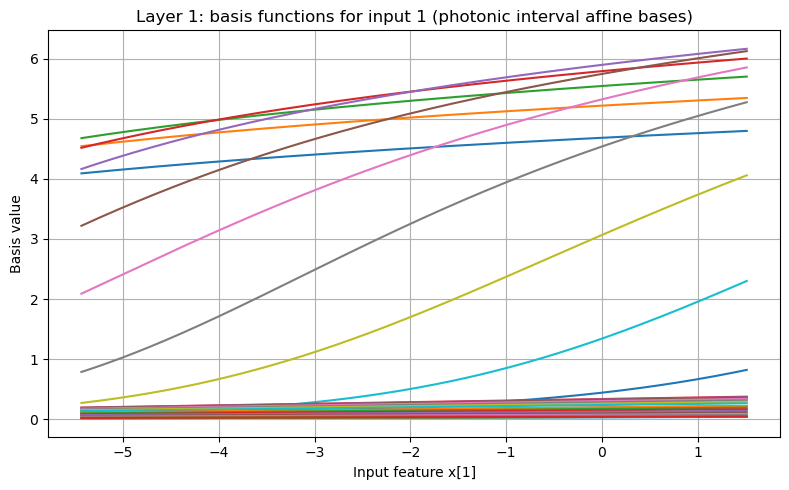

In [80]:
model_group.eval()
with torch.no_grad():
    _, activations_g = model_group(x_train, return_all=True)
z_g = activations_g[1]
z_g_min, z_g_max = z_g.min().item(), z_g.max().item()
print("hidden min:", z_g_min)
print("hidden max:", z_g_max)

model_group.plot_basis_functions(layer_idx=0, in_idx=0, x_range=(x_min_test, x_max_test),
                                        mat_export_path="sparse_group_basis_functions_L0_in0.mat", mat_export_dir=mat_folder)
model_group.plot_basis_functions(layer_idx=0, in_idx=1, x_range=(x_min_test, x_max_test),
                                        mat_export_path="sparse_group_basis_functions_L0_in1.mat", mat_export_dir=mat_folder)
model_group.plot_basis_functions(layer_idx=1, in_idx=0, x_range=(z_g_min, z_g_max),
                                        mat_export_path="sparse_group_basis_functions_L1_in0.mat", mat_export_dir=mat_folder)
model_group.plot_basis_functions(layer_idx=1, in_idx=1, x_range=(z_g_min, z_g_max),
                                        mat_export_path="sparse_group_basis_functions_L1_in1.mat", mat_export_dir=mat_folder)

Saved MATLAB plot data to: sparse_221_exports/sparse_group_target_approximation_0.5_varied_x0.mat


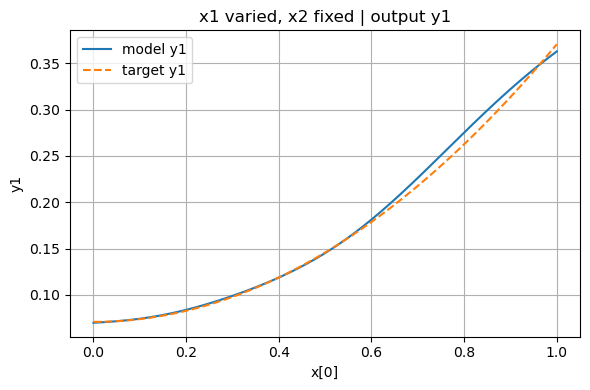

Saved MATLAB plot data to: sparse_221_exports/sparse_group_target_approximation_0.5_varied_x1.mat


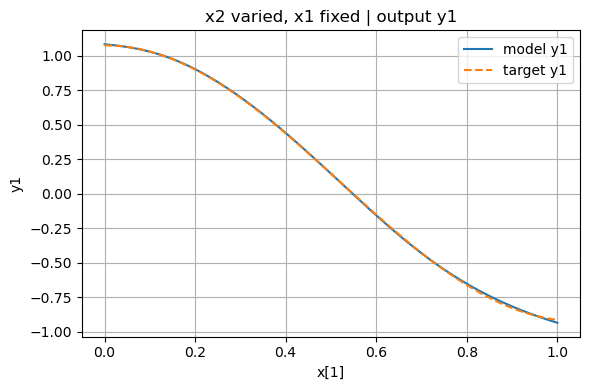

In [81]:
model_group.plot_target_approximation(
    target_fn=target_fn,
    x_range=(x_min_test, x_max_test),
    fixed_values=[0.5, 0.5],
    resolution=400,
    mat_export_prefix="sparse_group_target_approximation_0.5",
    mat_export_dir=mat_folder,
)